### 1. Imports and dataset location

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from sklearn.base import BaseEstimator, TransformerMixin

RANDOM_STATE = 42
DATA_DIR = Path("Dataset")

if not DATA_DIR.is_dir():
    alternatives = [Path("att_faces"), Path("orl_faces"), Path("ORL"), Path("faces")]
    DATA_DIR = next((path for path in alternatives if path.is_dir()), None)

if DATA_DIR is None:
    raise FileNotFoundError(
        "Dataset folder not found. Place the ORL subject folders inside a folder "
        "named 'Dataset' beside this notebook."
    )

print("Dataset directory:", DATA_DIR.resolve())

Dataset directory: D:\College\DS605\local\202618038_Lab_7\Dataset


### 2. Load images, labels, and inspect pixel data

In [2]:
subject_dirs = sorted(
    [p for p in DATA_DIR.iterdir() if p.is_dir() and p.name.lower().startswith("s")],
    key=lambda p: int(p.name[1:]) if p.name[1:].isdigit() else p.name
)

if not subject_dirs:
    raise FileNotFoundError(
        f"No subject folders such as s1, s2, ... found inside {DATA_DIR.resolve()}."
    )

image_paths, images_2d, labels = [], [], []

for subject_dir in subject_dirs:
    if not subject_dir.name[1:].isdigit():
        continue
    subject_label = int(subject_dir.name[1:])
    pgm_files = sorted(
        p for p in subject_dir.iterdir()
        if p.is_file() and p.suffix.lower() == ".pgm"
    )

    for image_path in pgm_files:
        with Image.open(image_path) as image:
            image_array = np.asarray(image.convert("L"), dtype=np.uint8)
        image_paths.append(image_path)
        images_2d.append(image_array)
        labels.append(subject_label)

if not images_2d:
    raise FileNotFoundError(f"No .pgm images found under {DATA_DIR.resolve()}.")

image_shape = images_2d[0].shape
if any(im.shape != image_shape for im in images_2d):
    raise ValueError("All images must have the same dimensions.")

images_2d = np.stack(images_2d)
y = np.asarray(labels, dtype=int)
height, width = image_shape
X = images_2d.reshape(len(images_2d), -1).astype(np.float64)

print("Number of images:", len(X))
print("Number of subjects:", len(np.unique(y)))
print("Image dimensions (height, width):", image_shape)
print("Flattened feature matrix:", X.shape)
print("Pixel intensity range:", int(images_2d.min()), "to", int(images_2d.max()))
print("Example image path:", image_paths[0])
print("Example subject label:", y[0])
print("First 20 flattened pixel values:", X[0, :20].astype(int))

Number of images: 400
Number of subjects: 40
Image dimensions (height, width): (112, 92)
Flattened feature matrix: (400, 10304)
Pixel intensity range: 0 to 251
Example image path: Dataset\s1\1.pgm
Example subject label: 1
First 20 flattened pixel values: [48 49 45 47 49 57 39 42 53 49 53 60 76 91 99 95 80 75 66 54]


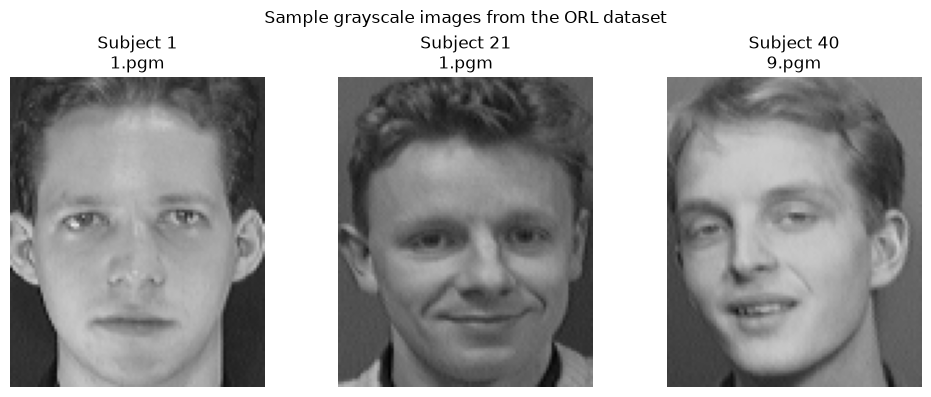

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(10, 4))
sample_indices = [0, len(images_2d) // 2, len(images_2d) - 1]

for ax, idx in zip(axes, sample_indices):
    ax.imshow(images_2d[idx], cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Subject {y[idx]}\n{image_paths[idx].name}")
    ax.axis("off")

plt.suptitle("Sample grayscale images from the ORL dataset")
plt.tight_layout()
plt.show()

### 3. Reproducible train-test split

In [4]:
X_train, X_test, y_train, y_test, paths_train, paths_test = train_test_split(
    X, y, image_paths,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

all_subjects = set(np.unique(y))
assert set(np.unique(y_train)) == all_subjects
assert set(np.unique(y_test)) == all_subjects

print("Training matrix:", X_train.shape)
print("Test matrix:", X_test.shape)
print("Subjects in training:", len(np.unique(y_train)))
print("Subjects in test:", len(np.unique(y_test)))

split_summary = pd.DataFrame({
    "Training images": pd.Series(y_train).value_counts().sort_index(),
    "Test images": pd.Series(y_test).value_counts().sort_index()
}).fillna(0).astype(int)
display(split_summary.head(10))

Training matrix: (280, 10304)
Test matrix: (120, 10304)
Subjects in training: 40
Subjects in test: 40


,Training images,Test images
1,7,3
2,7,3
3,7,3
4,7,3
5,7,3
6,7,3
7,7,3
8,7,3
9,7,3
10,7,3


### 4. Mean face and PCA by Gram-matrix eigendecomposition

In [5]:
mean_face = X_train.mean(axis=0)
X_train_centered = X_train - mean_face

gram_matrix = X_train_centered @ X_train_centered.T
eigenvalues_gram, eigenvectors_gram = np.linalg.eigh(gram_matrix)

sort_idx = np.argsort(eigenvalues_gram)[::-1]
eigenvalues_gram = eigenvalues_gram[sort_idx]
eigenvectors_gram = eigenvectors_gram[:, sort_idx]

tol = np.finfo(float).eps * max(gram_matrix.shape) * max(float(eigenvalues_gram[0]), 1.0)
valid = eigenvalues_gram > tol
eigenvalues_gram = eigenvalues_gram[valid]
eigenvectors_gram = eigenvectors_gram[:, valid]

components_eig = (
    X_train_centered.T @ eigenvectors_gram
) / np.sqrt(eigenvalues_gram)[None, :]
components_eig /= np.linalg.norm(components_eig, axis=0, keepdims=True)

print("Mean face vector shape:", mean_face.shape)
print("Centered training matrix:", X_train_centered.shape)
print("Gram matrix shape:", gram_matrix.shape)
print("Principal directions from eigendecomposition:", components_eig.shape)

Mean face vector shape: (10304,)
Centered training matrix: (280, 10304)
Gram matrix shape: (280, 280)
Principal directions from eigendecomposition: (10304, 279)


### 5. PCA by SVD and comparison with eigendecomposition

In [6]:
_, singular_values, Vt = np.linalg.svd(X_train_centered, full_matrices=False)
components_svd = Vt.T

explained_variance = singular_values ** 2 / (len(X_train) - 1)
explained_variance_ratio = explained_variance / explained_variance.sum()
cumulative_explained_variance = np.cumsum(explained_variance_ratio)

n_compare = min(10, components_eig.shape[1], components_svd.shape[1])
direction_similarity = np.abs(
    np.sum(components_eig[:, :n_compare] * components_svd[:, :n_compare], axis=0)
)

comparison_df = pd.DataFrame({
    "Principal component": np.arange(1, n_compare + 1),
    "Absolute cosine similarity": direction_similarity
})
display(comparison_df)

print("SVD component matrix shape:", components_svd.shape)
print(
    "Maximum deviation of leading direction similarity from 1:",
    float(np.max(np.abs(1 - direction_similarity)))
)

,Principal component,Absolute cosine similarity
0,1,1.0
1,2,1.0
2,3,1.0
3,4,1.0
4,5,1.0
5,6,1.0
6,7,1.0
7,8,1.0
8,9,1.0
9,10,1.0


SVD component matrix shape: (10304, 280)
Maximum deviation of leading direction similarity from 1: 2.55351295663786e-15


### 6. Cumulative explained variance and 90% component selection

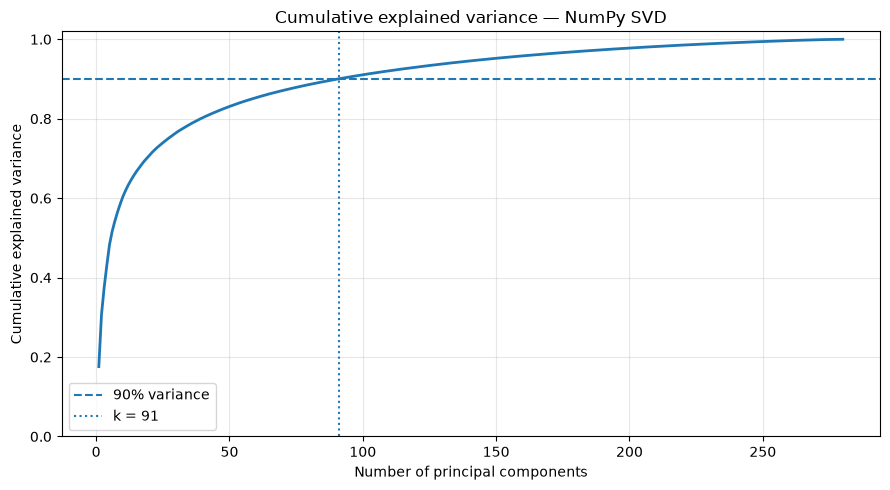

Minimum components retaining at least 90% variance: 91
Cumulative variance at k=91: 90.0473%
Cumulative variance at k=90: 89.9268%


In [7]:
k90 = int(np.searchsorted(cumulative_explained_variance, 0.90) + 1)

plt.figure(figsize=(9, 5))
plt.plot(
    np.arange(1, len(cumulative_explained_variance) + 1),
    cumulative_explained_variance,
    linewidth=2
)
plt.axhline(0.90, linestyle="--", label="90% variance")
plt.axvline(k90, linestyle=":", label=f"k = {k90}")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative explained variance — NumPy SVD")
plt.ylim(0, 1.02)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Minimum components retaining at least 90% variance: {k90}")
print(f"Cumulative variance at k={k90}: {cumulative_explained_variance[k90 - 1]:.4%}")
if k90 > 1:
    print(f"Cumulative variance at k={k90 - 1}: {cumulative_explained_variance[k90 - 2]:.4%}")

### 7. Visualize eigenfaces

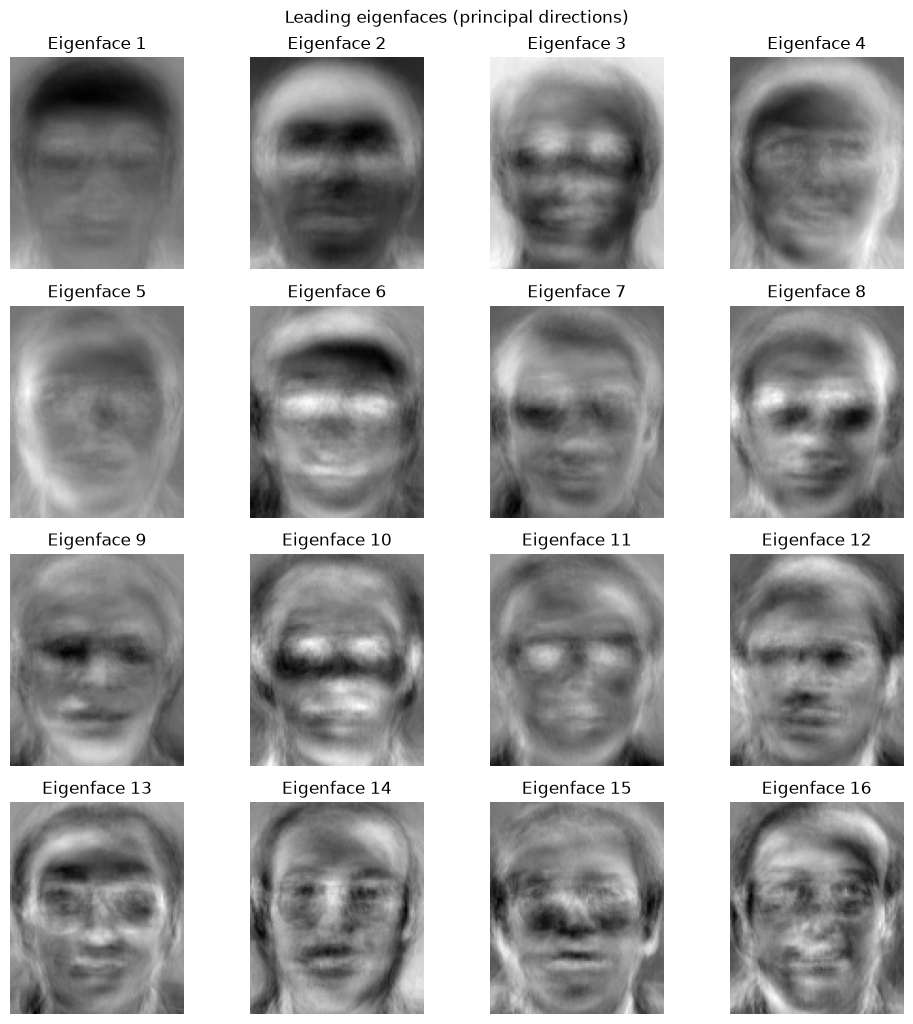

In [8]:
n_eigenfaces = min(16, components_svd.shape[1])
n_cols = 4
n_rows = int(np.ceil(n_eigenfaces / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(10, 2.6 * n_rows))
axes = np.asarray(axes).reshape(-1)

for i, ax in enumerate(axes):
    if i < n_eigenfaces:
        eigenface = components_svd[:, i].reshape(height, width)
        limit = np.max(np.abs(eigenface))
        ax.imshow(eigenface, cmap="gray", vmin=-limit, vmax=limit)
        ax.set_title(f"Eigenface {i + 1}")
    ax.axis("off")

plt.suptitle("Leading eigenfaces (principal directions)")
plt.tight_layout()
plt.show()

### 8. PCA projection, reconstruction, and storage comparison

In [9]:
components_90 = components_svd[:, :k90]
Z_train = (X_train - mean_face) @ components_90
Z_test = (X_test - mean_face) @ components_90
Z_all = (X - mean_face) @ components_90

print("Reduced training representation:", Z_train.shape)
print("Reduced test representation:", Z_test.shape)
print("Reduced representation of all images:", Z_all.shape)

n_reconstruct = min(5, len(X_test))
X_test_reconstructed = Z_test[:n_reconstruct] @ components_90.T + mean_face
reconstruction_rmse = np.sqrt(
    np.mean((X_test[:n_reconstruct] - X_test_reconstructed) ** 2)
)
print(f"Reconstruction RMSE for {n_reconstruct} test images: {reconstruction_rmse:.4f}")

Reduced training representation: (280, 91)
Reduced test representation: (120, 91)
Reduced representation of all images: (400, 91)
Reconstruction RMSE for 5 test images: 19.7143


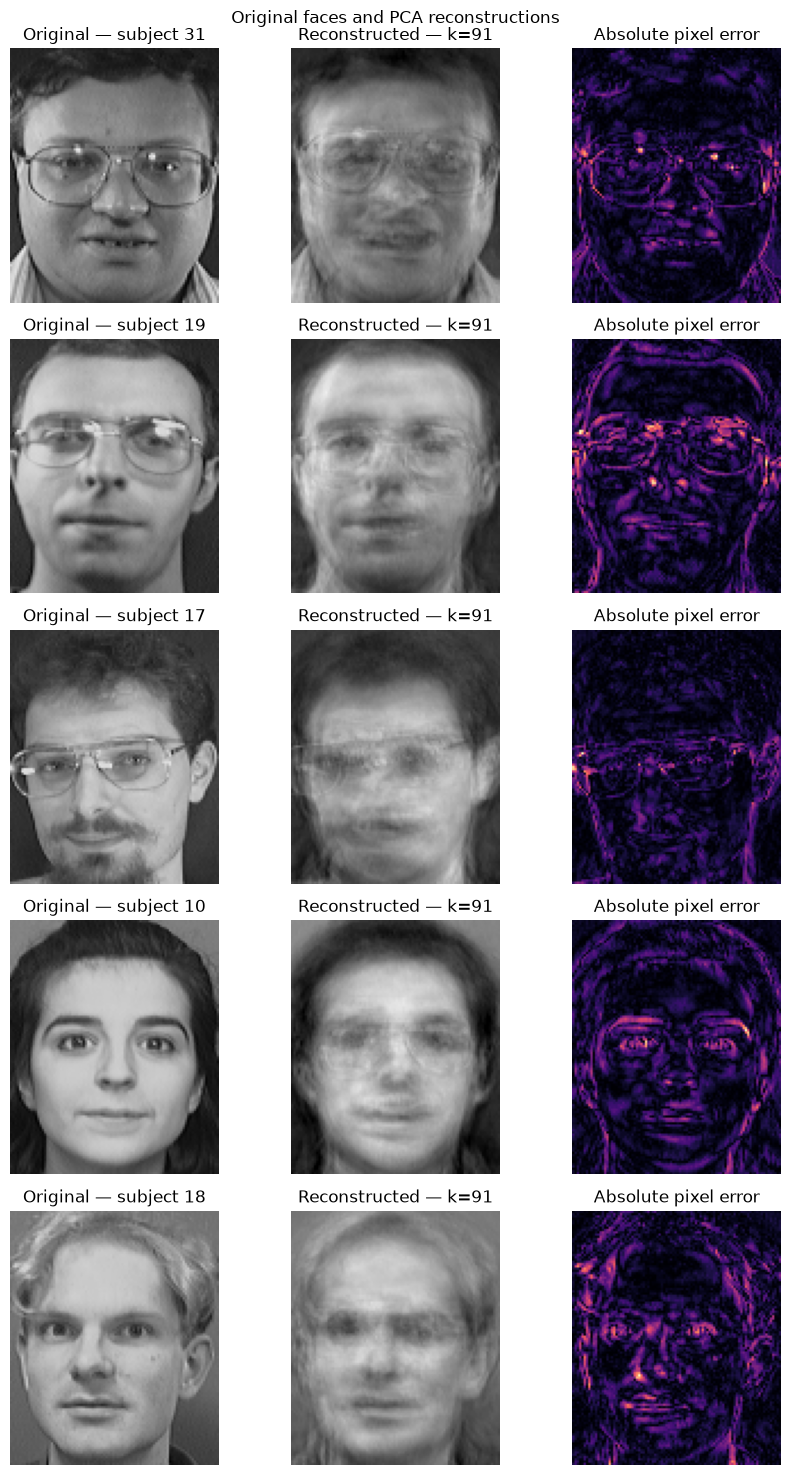

In [10]:
fig, axes = plt.subplots(n_reconstruct, 3, figsize=(9, 3 * n_reconstruct))
axes = np.atleast_2d(axes)

for i in range(n_reconstruct):
    original = X_test[i].reshape(height, width)
    reconstructed = X_test_reconstructed[i].reshape(height, width)
    error_image = np.abs(original - reconstructed)

    axes[i, 0].imshow(original, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title(f"Original — subject {y_test[i]}")
    axes[i, 1].imshow(reconstructed, cmap="gray", vmin=0, vmax=255)
    axes[i, 1].set_title(f"Reconstructed — k={k90}")
    axes[i, 2].imshow(error_image, cmap="magma")
    axes[i, 2].set_title("Absolute pixel error")

    for ax in axes[i]:
        ax.axis("off")

plt.suptitle("Original faces and PCA reconstructions")
plt.tight_layout()
plt.show()

In [11]:
original_storage_bytes = X.nbytes
pca_storage_bytes = Z_all.nbytes
storage_reduction_percent = (1 - pca_storage_bytes / original_storage_bytes) * 100

storage_comparison = pd.DataFrame({
    "Representation": ["Original flattened pixels", f"PCA coefficients (k={k90})"],
    "Shape": [str(X.shape), str(Z_all.shape)],
    "NumPy array storage (bytes)": [original_storage_bytes, pca_storage_bytes]
})
display(storage_comparison)

print(f"Representation storage reduction: {storage_reduction_percent:.2f}%")
print(
    "Note: this compares image-array storage only; it excludes the mean face and "
    "PCA component matrix needed for encoding/decoding."
)

,Representation,Shape,NumPy array storage (bytes)
0,Original flattened pixels,"(400, 10304)",32972800
1,PCA coefficients (k=91),"(400, 91)",291200


Representation storage reduction: 99.12%
Note: this compares image-array storage only; it excludes the mean face and PCA component matrix needed for encoding/decoding.


### 9. Similarity-based recognition using nearest neighbors

In [12]:
def nearest_neighbor_predict(X_reference, y_reference, X_query):
    """Predict query labels using Euclidean nearest-neighbor matching."""
    predictions = []
    nearest_indices = []

    for query in X_query:
        distances = np.linalg.norm(X_reference - query, axis=1)
        nearest_idx = int(np.argmin(distances))
        predictions.append(y_reference[nearest_idx])
        nearest_indices.append(nearest_idx)

    return np.asarray(predictions), np.asarray(nearest_indices)


y_pred_raw, raw_match_idx = nearest_neighbor_predict(X_train, y_train, X_test)
y_pred_pca, pca_match_idx = nearest_neighbor_predict(Z_train, y_train, Z_test)

raw_accuracy = accuracy_score(y_test, y_pred_raw)
pca_accuracy = accuracy_score(y_test, y_pred_pca)

print(f"Raw-pixel nearest-neighbor accuracy: {raw_accuracy:.2%} ({np.sum(y_pred_raw == y_test)}/{len(y_test)})")
print(f"PCA nearest-neighbor accuracy: {pca_accuracy:.2%} ({np.sum(y_pred_pca == y_test)}/{len(y_test)})")

Raw-pixel nearest-neighbor accuracy: 96.67% (116/120)
PCA nearest-neighbor accuracy: 96.67% (116/120)


Correct PCA matches: 116
Incorrect PCA matches: 4


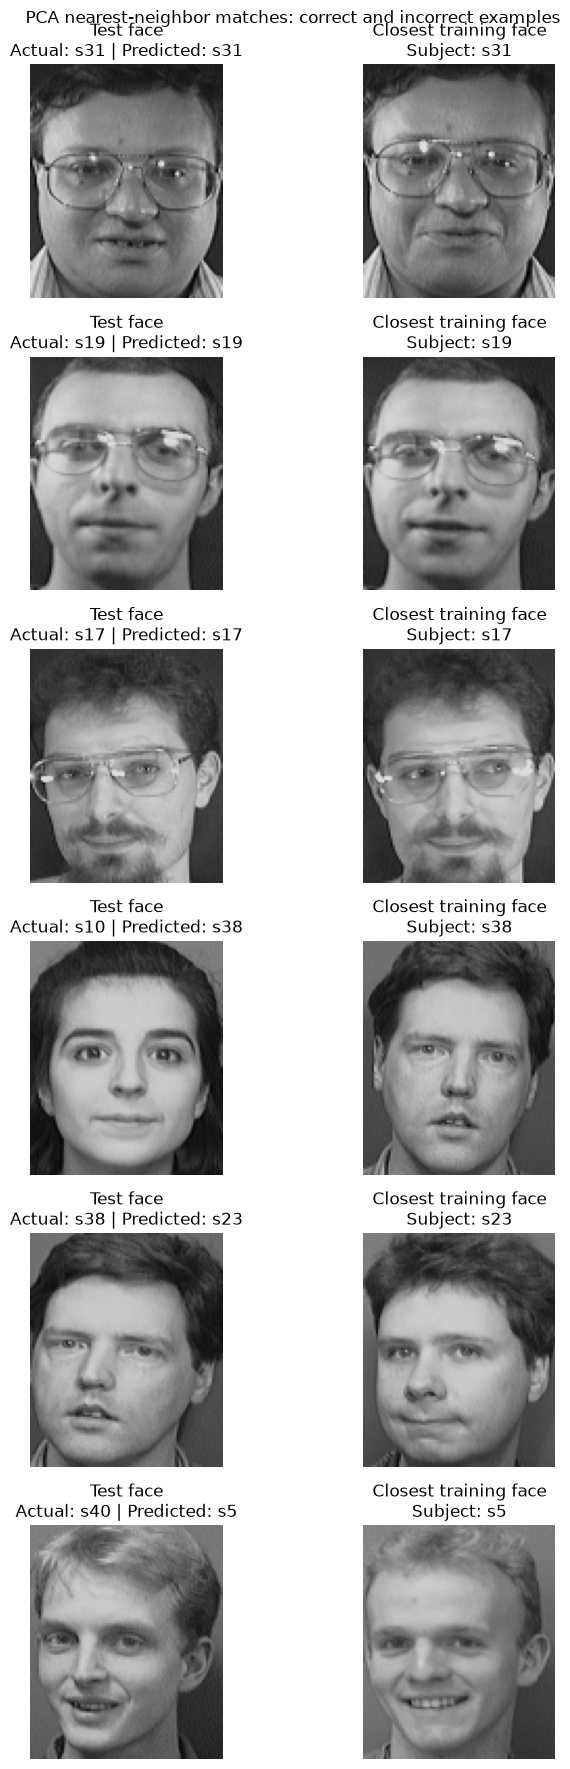

In [13]:
correct_positions = np.where(y_pred_pca == y_test)[0]
incorrect_positions = np.where(y_pred_pca != y_test)[0]
print("Correct PCA matches:", len(correct_positions))
print("Incorrect PCA matches:", len(incorrect_positions))

chosen = np.concatenate([correct_positions[:3], incorrect_positions[:3]])

if len(chosen) == 0:
    print("No test examples available to display.")
else:
    fig, axes = plt.subplots(len(chosen), 2, figsize=(8, 3 * len(chosen)))
    axes = np.atleast_2d(axes)

    for row, test_idx in enumerate(chosen):
        train_idx = pca_match_idx[test_idx]

        axes[row, 0].imshow(X_test[test_idx].reshape(height, width), cmap="gray", vmin=0, vmax=255)
        axes[row, 0].set_title(
            f"Test face\nActual: s{y_test[test_idx]} | Predicted: s{y_pred_pca[test_idx]}"
        )
        axes[row, 0].axis("off")

        axes[row, 1].imshow(X_train[train_idx].reshape(height, width), cmap="gray", vmin=0, vmax=255)
        axes[row, 1].set_title(f"Closest training face\nSubject: s{y_train[train_idx]}")
        axes[row, 1].axis("off")

    plt.suptitle("PCA nearest-neighbor matches: correct and incorrect examples")
    plt.tight_layout()
    plt.show()

### 10. Traditional classifiers with NumPy PCA inside cross-validation

In [14]:
class NumPyPCA(BaseEstimator, TransformerMixin):
    """PCA transformer implemented with NumPy SVD."""

    def __init__(self, n_components=30):
        self.n_components = n_components

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.mean_ = X.mean(axis=0)
        X_centered = X - self.mean_
        _, singular_values, Vt = np.linalg.svd(X_centered, full_matrices=False)

        max_components = min(Vt.shape[0], X.shape[0] - 1)
        if not 1 <= self.n_components <= max_components:
            raise ValueError(
                f"n_components must be between 1 and {max_components}; got {self.n_components}."
            )

        self.components_ = Vt[:self.n_components].T
        self.singular_values_ = singular_values[:self.n_components]
        return self

    def transform(self, X):
        X = np.asarray(X, dtype=float)
        return (X - self.mean_) @ self.components_

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
component_options = sorted(set(
    k for k in [30, 60, k90, 120]
    if 1 <= k <= min(X_train.shape[0] - 2, X_train.shape[1])
))

model_configs = {
    "KNN": (
        KNeighborsClassifier(),
        {
            "model__n_neighbors": [1, 3, 5, 7],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        }
    ),
    "Logistic Regression": (
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        {"model__C": [0.01, 0.1, 1, 10]}
    ),
    "SVM (RBF)": (
        SVC(),
        {
            "model__C": [0.1, 1, 10, 100],
            "model__gamma": ["scale", 0.001, 0.01]
        }
    )
}

corrected_results = []
corrected_models = {}
cv_component_scores = []

for model_name, (estimator, model_grid) in model_configs.items():
    pipeline = Pipeline([
        ("pca", NumPyPCA()),
        ("scaler", StandardScaler()),
        ("model", estimator)
    ])

    param_grid = {"pca__n_components": component_options, **model_grid}
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grid,
        scoring="accuracy",
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=False
    )

    search.fit(X_train, y_train)
    test_predictions = search.predict(X_test)
    test_accuracy = accuracy_score(y_test, test_predictions)

    corrected_results.append({
        "Model": model_name,
        "PCA components": search.best_params_["pca__n_components"],
        "CV accuracy (%)": round(search.best_score_ * 100, 2),
        "Test accuracy (%)": round(test_accuracy * 100, 2),
        "Best settings": str(search.best_params_)
    })
    corrected_models[model_name] = search.best_estimator_

    cv_results = pd.DataFrame(search.cv_results_)
    cv_results["PCA components"] = cv_results["param_pca__n_components"].astype(int)
    for component_count, group in cv_results.groupby("PCA components"):
        cv_component_scores.append({
            "Model": model_name,
            "PCA components": component_count,
            "Best CV accuracy (%)": group["mean_test_score"].max() * 100
        })

    print(f"\n{model_name}")
    print("Best settings:", search.best_params_)
    print(f"Best cross-validation accuracy: {search.best_score_:.2%}")
    print(f"Held-out test accuracy: {test_accuracy:.2%}")

corrected_results_df = pd.DataFrame(corrected_results).sort_values(
    "Test accuracy (%)", ascending=False
).reset_index(drop=True)

print("\nTraditional classifier results:")
display(corrected_results_df)


KNN
Best settings: {'model__n_neighbors': 1, 'model__p': 1, 'model__weights': 'uniform', 'pca__n_components': 30}
Best cross-validation accuracy: 92.14%
Held-out test accuracy: 93.33%

Logistic Regression
Best settings: {'model__C': 10, 'pca__n_components': 30}
Best cross-validation accuracy: 93.93%
Held-out test accuracy: 96.67%

SVM (RBF)
Best settings: {'model__C': 10, 'model__gamma': 0.01, 'pca__n_components': 30}
Best cross-validation accuracy: 93.93%
Held-out test accuracy: 96.67%

Traditional classifier results:


,Model,PCA components,CV accuracy (%),Test accuracy (%),Best settings
0,Logistic Regression,30,93.93,96.67,"{'model__C': 10, 'pca__n_components': 30}"
1,SVM (RBF),30,93.93,96.67,"{'model__C': 10, 'model__gamma': 0.01, 'pca__n..."
2,KNN,30,92.14,93.33,"{'model__n_neighbors': 1, 'model__p': 1, 'mode..."


### 11. Final comparison table and component-count experiment

In [16]:
baseline_results = pd.DataFrame([
    {
        "Model": "Raw-pixel nearest neighbor",
        "PCA components": 0,
        "CV accuracy (%)": np.nan,
        "Test accuracy (%)": round(raw_accuracy * 100, 2),
        "Best settings": "Euclidean distance on raw pixels"
    },
    {
        "Model": "PCA nearest neighbor",
        "PCA components": k90,
        "CV accuracy (%)": np.nan,
        "Test accuracy (%)": round(pca_accuracy * 100, 2),
        "Best settings": f"Euclidean distance; k={k90} (at least 90% variance)"
    }
])

final_results = pd.concat([baseline_results, corrected_results_df], ignore_index=True)
display(final_results)
final_results.to_csv("recognition_comparison.csv", index=False)
print("Saved comparison table to recognition_comparison.csv")

,Model,PCA components,CV accuracy (%),Test accuracy (%),Best settings
0,Raw-pixel nearest neighbor,0,NaN,96.67,Euclidean distance on raw pixels
1,PCA nearest neighbor,91,NaN,96.67,Euclidean distance; k=91 (at least 90% variance)
2,Logistic Regression,30,93.93,96.67,"{'model__C': 10, 'pca__n_components': 30}"
3,SVM (RBF),30,93.93,96.67,"{'model__C': 10, 'model__gamma': 0.01, 'pca__n..."
4,KNN,30,92.14,93.33,"{'model__n_neighbors': 1, 'model__p': 1, 'mode..."


Saved comparison table to recognition_comparison.csv


### 12. Detailed SVM evaluation and error inspection

In [17]:
best_svm = corrected_models["SVM (RBF)"]
y_pred_svm = best_svm.predict(X_test)

print(f"Final SVM test accuracy: {accuracy_score(y_test, y_pred_svm):.2%}")
print("\nClassification report:")
print(classification_report(y_test, y_pred_svm, zero_division=0))

misclassified_indices = np.where(y_pred_svm != y_test)[0]
print(f"Correct predictions: {len(y_test) - len(misclassified_indices)}/{len(y_test)}")
print(f"Incorrect predictions: {len(misclassified_indices)}")

Final SVM test accuracy: 96.67%

Classification report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00         3
           2       1.00      1.00      1.00         3
           3       1.00      1.00      1.00         3
           4       1.00      1.00      1.00         3
           5       0.75      1.00      0.86         3
           6       1.00      1.00      1.00         3
           7       1.00      1.00      1.00         3
           8       1.00      1.00      1.00         3
           9       1.00      1.00      1.00         3
          10       1.00      0.67      0.80         3
          11       1.00      1.00      1.00         3
          12       1.00      1.00      1.00         3
          13       1.00      1.00      1.00         3
          14       1.00      1.00      1.00         3
          15       0.75      1.00      0.86         3
          16       1.00      1.00      1.00         3
          17       1.00  

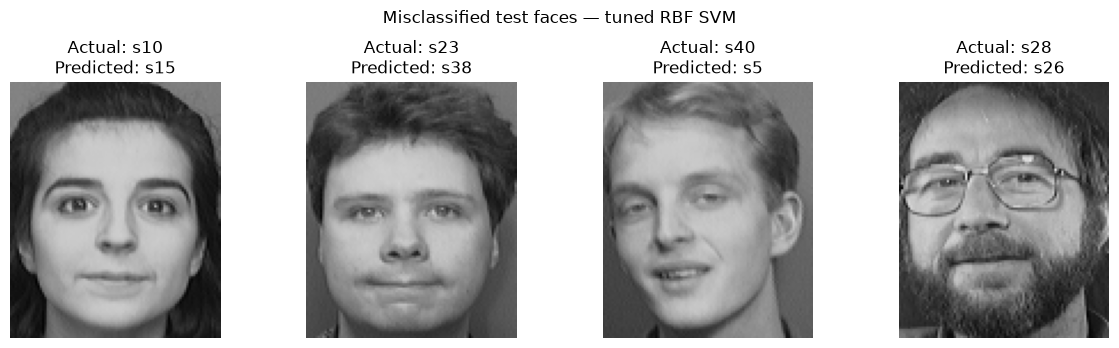

In [18]:
if len(misclassified_indices) == 0:
    print("No misclassified test images.")
else:
    n_show = min(8, len(misclassified_indices))
    n_cols = 4
    n_rows = int(np.ceil(n_show / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 3.5 * n_rows))
    axes = np.asarray(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for i, test_idx in enumerate(misclassified_indices[:n_show]):
        axes[i].imshow(X_test[test_idx].reshape(height, width), cmap="gray", vmin=0, vmax=255)
        axes[i].set_title(f"Actual: s{y_test[test_idx]}\nPredicted: s{y_pred_svm[test_idx]}")
        axes[i].axis("off")

    plt.suptitle("Misclassified test faces — tuned RBF SVM")
    plt.tight_layout()
    plt.show()

### Conclusion

The experiment demonstrates that PCA can substantially reduce the dimensionality of face images while retaining useful facial information for recognition. Using 91 principal components preserved 90.0473% of the training variance and reduced coefficient-array storage by 99.12%. Both raw-pixel and PCA-space nearest-neighbor matching achieved 96.67% test accuracy. Among the traditional classifiers, Logistic Regression and RBF SVM achieved the highest test accuracy of 96.67%, outperforming KNN at 93.33%. The results show that a compact PCA representation can support effective face recognition, although reconstruction involves information loss and performance may vary with the data split, component count, and classifier settings.